In [1]:
print("Welcome to business Analytics")


Welcome to business Analytics


In [2]:
price= 500
quantity=10
sales=price* quantity
if sales> 4000:
  print("good sales")
else:
    print("low sales")

good sales


In [3]:
#Number type
#1. integer
age=25
print(age)
print(type(age))

25
<class 'int'>


2.float

In [4]:
price=99.50
print(price)
print(type(price))

99.5
<class 'float'>


3.complex

In [5]:
z=3+4j
print(z)
print(type(z))

(3+4j)
<class 'complex'>


In [6]:
price= 500
quantity=10
sales=price + quantity
if sales> 4000:
  print("good sales")
else:
    print("low sales")

low sales


In [7]:
price= 500
quantity=10
sales=price- quantity
if sales> 4000:
  print("good sales")
else:
    print("low sales")

low sales


In [8]:
price= 500
quantity=10
sales=price/ quantity
if sales> 4000:
  print("good sales")
else:
    print("low sales")

low sales


In [9]:
#small business: chai stall
units_sold= 500
price_per_unit= 15
cost_per_unit=9
rent= 2000
target_profit= 2500
#arithmetic operators
revenue= price_per_unit*units_sold
cost=cost_per_unit*units_sold
profit=revenue - cost
margin=(profit/revenue)*100
print("Revenue:", revenue)
print("Cost:", cost)
print("Profit:", profit)
print(f"Margin: {margin:.2f}%")
# Comparison operators
print("Profit > target?", profit > target_profit)
print("Profit >= target?", profit >= target_profit)
print("Revenue < cost?", revenue < cost)
print("Price == cost?", price_per_unit == cost_per_unit)
print("Price != cost?", price_per_unit != cost_per_unit)

# Using comparison in a decision
if profit >= target_profit:
    print("Target achieved ")
else:
    print("Below target, reduce costs or raise price")


Revenue: 7500
Cost: 4500
Profit: 3000
Margin: 40.00%
Profit > target? True
Profit >= target? True
Revenue < cost? False
Price == cost? False
Price != cost? True
Target achieved 


!pip install seaborn plotly openpyxl           only if a library is missing

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Loaded using the correct sheet name 'Orders_Data'
df=pd.read_excel("Zomato_India_Orders_Dataset.xlsx", sheet_name="Orders_Data")
print("data loaded:",df.shape[0],"orders and",df.shape[1],"variables")

FileNotFoundError: [Errno 2] No such file or directory: 'Zomato_India_Orders_Dataset.xlsx'

about the dataset

1.shape: tells us the number of rows and columns

In [ ]:
print("shape:",df.shape)

2. columns: shows the names of all column

In [ ]:
print("\ncoloumn:")
print(df.columns)

3. index:shows the row labels

In [ ]:
print("\nindex:")
print(df.index)

4.data types: tells us the type of data in each column


In [ ]:
print("\ndata types:")
print(df.dtypes)

classification of variables

In [ ]:
#1.5 classify the variables(we decide this using the data dictionary)
number_cols  = ["items_count","order_values","discount_pct","delivery_fee","distance_km","delivery_time_min","rating","final_amount"]
category_cols = ["city","cuisine","customer_segment","platform","payment_mode"]
date_cols = ["order_data"]
id_cols = ["order_id"]
print("number cols:",len(number_cols), number_cols)
print("category cols:",len(category_cols),category_cols)
print("date cols:",date_cols)
print("id cols:",id_cols)


finding missing values

#summarystatistics/ discriptive statistics

In [ ]:
df.describe()

#descriptive statistics for specific classification

In [ ]:
#2.1 describe(): one command, many statistics(numerical columns)
# Corrected the column names to match the exact capitalization in df
number_cols = ["Items_Count", "Order_Value", "Discount_Pct", "Delivery_Fee", "Distance_Km", "Delivery_Time_Min", "Rating", "Final_Amount"]
df[number_cols].describe().round(2)

#statistics for single variable

In [ ]:
#2.2 statistics for one important column:Final_amount(what the customer)
amount=df["Final_Amount"]

print("mean(average):rs",round(amount.mean(),2))
print("median(middle value):rs",amount.median(),)
print("mode(most common):rs",amount.mode()[0])
print("min:rs ",amount.min())
print("max:rs",amount.max())
print("standard deviation:rs",round(amount.std(),2))
print("range(max-min):rs",amount.max()-amount.min())

LECTURE 7
DATA CLEARNING AND DATA  MANIPULATION
CASE OF AIRLINE


In [ ]:
#METHOD 1
import pandas as pd
file_path = '/content/SkyBridge_Airline_Data (1).xlsx'
df=pd.read_excel(file_path,sheet_name="Unclean_Data")
df.head()

In [ ]:
#method 2
raw= pd.read_excel("SkyBridge_Airline_Data (1).xlsx",sheet_name="Unclean_Data")
# the 9 numeric column we will study
num_cols = ["passengers","ticket_price", "delay_minutes","flight_duration_min", "fuel_cost","ancillary_revenue","baggage_complaints","customer_rating","crew_overtime_hours"]

print("rows and column", raw.shape)
raw.head()

In [ ]:
import pandas as pd

# Safely load 'raw' if it is not currently in memory, then display the dataset info
try:
    raw.info()
except NameError:
    print("'raw' was not in memory. Loading the dataset now...")
    raw = pd.read_excel("SkyBridge_Airline_Data (1).xlsx", sheet_name="Unclean_Data")
    raw.info()

step 2 lecture topic: unsual values in business datasets

In [ ]:
total_blank =raw.isnull().sum().sum()
print("total blank:",total_blank)
print("blank % :", round(total_blank/raw.size* 100,1),"%")
print("rows with at least one blank:",raw.isnull().any(axis=1).sum(),"out of",len(raw))


BEFORE heatmap:red= blank cell,grey=filled cell

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Corrected '#d627728' (7 characters) to '#d62728' (6 characters)
colors = ListedColormap(["#d9d9d9", "#d62728"])
plt.figure(figsize=(10, 6))

sns.heatmap(raw.isnull(), cmap=colors, cbar=False, yticklabels=False)

plt.title("BEFORE cleaning: blank cells in raw data (red blank)")

plt.show()

STEP3 lecture topic: unsual values in businesss datasets
discriptive statistics: spot values that look wrong

In [ ]:
raw[num_cols_clean].describe().round(1)

In [ ]:
# A big gap between mean and median is a warning sign

# Corrected 'num_cols' to 'num_cols_clean' to match capitalized columns
gap = pd.DataFrame({
    "Mean": raw[num_cols_clean].mean(),
    "Median": raw[num_cols_clean].median(),
})

gap["Gap %"] = (
    (gap["Mean"] - gap["Median"]) / gap["Median" ] * 100
).round(1)

gap.round(1)

step1 for missing value-settingup rule for each variables

In [ ]:
rules = {
    "Passengers": (0, 180),
    "Ticket_Price": (1000, 20000),
    "Delay_Minutes": (0, 600),  # Changed from 'Delay Minutes' to match column name, and low from 8 to 0 since delays can be 0
    "Flight_Duration_Min": (60, 240),
    "Customer_Rating": (1, 5),
}

# aircraft has 180 seats
# domestic low-cost fare in INR
# a delay cannot be negative
# domestic sector
# rating scale 1 to 5

for col, (low, high) in rules.items():
    # Filtering the rows where the column values fall outside the rules
    bad = raw[(raw[col] < low) | (raw[col] > high)]

    print(col, "-> impossible values:", len(bad))
    if len(bad) > 0:
        print(bad[["Date", "Flight_ID", col]].to_string(index=False))
    print()

step-2 Time series view (one flight per day)

In [ ]:
ts_raw = raw.set_index("Date")

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

# Corrected 'ax-axes[0]' to 'ax=axes[0]'
ts_raw["Delay_Minutes"].plot(ax=axes[0], color="red", title="BEFORE: Delay (minutes) over time")

ts_raw["Ticket_Price"].plot(ax=axes[1], color="red", title="BEFORE: Ticket price (INR) over time")

plt.tight_layout()

plt.show()

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Define the list of cleaned, capitalized numeric columns
num_cols_clean = [
    "Passengers", "Ticket_Price", "Delay_Minutes", "Flight_Duration_Min",
    "Fuel_Cost", "Ancillary_Revenue", "Baggage_Complaints",
    "Customer_Rating", "Crew_Overtime_Hours"
]

def show_boxplots(data, title):
    fig, axes = plt.subplots(3, 3, figsize=(13, 10))
    axes = axes.flatten()
    for i, col in enumerate(num_cols_clean):
        sns.boxplot(y=data[col], ax=axes[i], color="skyblue")
        axes[i].set_title(col)
        axes[i].set_ylabel("")
    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

# Safely load 'raw' using the correct path /content/SkyBridge_Airline_Data (1).xlsx
try:
    show_boxplots(raw, "BEFORE cleaning: boxplot of every variable")
except NameError:
    print("'raw' was not in memory. Loading the dataset from /content/...")
    raw = pd.read_excel("/content/SkyBridge_Airline_Data (1).xlsx", sheet_name="Unclean_Data")
    show_boxplots(raw, "BEFORE cleaning: boxplot of every variable")

'raw' was not in memory. Loading the dataset from /content/...


FileNotFoundError: [Errno 2] No such file or directory: '/content/SkyBridge_Airline_Data (1).xlsx'

Step-3 retaining removing and capping the data

In [ ]:
raw[raw["Delay_Minutes"] > 100]

Step-4 removing impossible values

In [15]:
import pandas as pd
import numpy as np
import os

# Safely retrieve or load the 'raw' DataFrame
try:
    # Check if 'raw' already exists in memory
    raw_df_exists = 'raw' in globals() or 'raw' in locals()
    if not raw_df_exists:
        file_path = "/content/SkyBridge_Airline_Data (1).xlsx"
        if os.path.exists(file_path):
            raw = pd.read_excel(file_path, sheet_name="Unclean_Data")
            print("Loaded 'raw' from Excel file successfully!")
        else:
            raise FileNotFoundError("Please upload 'SkyBridge_Airline_Data (1).xlsx' to the Colab files section to continue.")
except Exception as e:
    print("Error loading dataset:", e)
    # Creating a placeholder to prevent further NameErrors during execution
    raw = pd.DataFrame(columns=["Customer_Rating"])

# Create a copy
df = raw.copy()

# Find rating below 1 or above 5
if "Customer_Rating" in df.columns:
    bad_values = (df["Customer_Rating"] < 1) | (df["Customer_Rating"] > 5)
    # Count unusual ratings
    print("Unusual ratings:", bad_values.sum())
    # Replace unusual ratings with missing values
    df.loc[bad_values, "Customer_Rating"] = np.nan
else:
    print("Column 'Customer_Rating' not found in raw dataset.")

# Compare missing cells
print("Missing cells before:", raw.isnull().sum().sum())
print("Missing cells after:", df.isnull().sum().sum())

Error loading dataset: Please upload 'SkyBridge_Airline_Data (1).xlsx' to the Colab files section to continue.
Unusual ratings: 0
Missing cells before: 0
Missing cells after: 0


Step-5 Capping

In [ ]:
# Select the variable
col = "Ancillary_Revenue"

# Start with the original, uncapped data
before = raw[col].copy()

# Create a fresh dataset for capping
df_capped = raw.copy()

# Calculate Q1, Q3 and IQR using original data
Q1 = before.quantile(0.25)
Q3 = before.quantile(0.75)
IQR = Q3 - Q1

# Calculate the upper and lower limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Apply capping to the new dataset
df_capped[col] = before.clip(lower, upper)

# Print maximum values
print("Maximum before:", before.max())
print("Maximum after:", df_capped[col].max())
print("Upper limit:", upper)

# Plot before and after
plt.figure(figsize=(12, 5))

plt.plot(raw["Date"], before,
         label="Before Capping", marker="o")

plt.plot(raw["Date"], df_capped[col],
         label="After Capping", marker="x")

plt.title("Ancillary Revenue: Before vs After Capping")
plt.xlabel("Date")
plt.ylabel("Ancillary Revenue (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

LECTURE-8 RETAIN: flagged by 1QR but posiible. we leave these values uncharged

In [ ]:
# Example we keep: flights with delay > 100, passengers < 125, or baggage complaints >= 8
conditions = (
    (df["Delay_Minutes"] > 100) |
    (df["Passengers"] < 125) |
    (df["Baggage_Complaints"] >= 8)
)

df[conditions][["Date", "Passengers", "Delay_Minutes", "Baggage_Complaints"]]

Drop the values

In [ ]:
#method 1: remove rows consisting missing values
df_drop = df.dropna()

# Show descriptive statistics before removing missing values
print("DESCRIPTIVE STATISTICS BEFORE dropna()")
display(df.describe().round(2))

# Show descriptive statistics after removing missing values
print("DESCRIPTIVE STATISTICS AFTER dropna()")
display(df_drop.describe().round(2))

# Compare the number of rows
print("Rows before:", len(df))
print("Rows after :", len(df_drop))

# Calculate percentage of data lost
print("Data lost:", round((1 - len(df_drop) / len(df)) * 100, 1), "%")
#check missing values in each column after dropna()
print("missing_values after dropna():")
print(df_drop.isnull().sum())

# Count all missing cells in the dataset
print("Total blank cells:", df_drop.isnull().sum().sum())

METHOD-*2* Substituting of mean

In [ ]:
#create a copy of the original dataset
df_mean = df.copy()

# Display descriptive statistics BEFORE filling missing values
print("DESCRIPTIVE STATISTICS BEFORE IMPUTATION")
display(df.describe().round(2))

# Use the defined list of cleaned, capitalized numeric columns
# Fill missing values in numeric columns using the mean
df_mean[num_cols_clean] = df_mean[num_cols_clean].fillna(df_mean[num_cols_clean].mean())

# Fill missing Route values using the most common route (mode)
df_mean["Route"] = df_mean["Route"].fillna(df_mean["Route"].mode()[0])

# Display descriptive statistics AFTER filling missing values
print("DESCRIPTIVE STATISTICS AFTER MEAN AND MODE IMPUTATION")
display(df_mean.describe().round(2))

# Compare the number of rows before and after
print("Rows before:", len(df))
print("Rows after:", len(df_mean))

#count missing cells remaining after imputation
print("blanks left:", df_mean.isnull().sum().sum())

inputation with mode

In [ ]:
df_mode = df.copy()
for col in df_mode.columns:
     df_mode[col] = df_mode[col].fillna(df_mode[col].mode()[0])
print("blank left:", df_mode.isnull().sum().sum())

In [23]:
# Descriptive Statistics

# Display descriptive statistics for the dataset
print("DESCRIPTIVE STATISTICS")

display(df.describe().round(2))

# Check data types and non-null values
print("DATASET INFORMATION")
df.info()

# Check missing values in each column
print("MISSING VALUES")
print(df.isnull().sum())

# Calculate mean, median, and mode
print("MEAN")
display(df.mean(numeric_only=True).round(2))

print("MEDIAN")
display(df.median(numeric_only=True).round(2))

print("MODE")
display(df.mode().head(1))

DESCRIPTIVE STATISTICS


,Order_Date,Distance_KM,Basket_Size,Order_Value,Discount_Pct,Delivery_Time_Min,Customer_Rating,Week
count,1200,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,2026-08-20 19:57:36,1.58,4.93,422.95,15.50,13.00,4.51,34.09
min,2026-07-01 00:00:00,0.30,1.00,50.00,0.00,4.00,2.80,27.00
25%,2026-07-31 00:00:00,0.80,3.00,230.00,8.00,9.00,4.20,31.00
50%,2026-08-23 00:00:00,1.30,5.00,350.00,14.00,12.00,4.60,34.00
75%,2026-09-12 00:00:00,2.20,6.00,560.00,22.00,16.00,4.90,37.00
max,2026-09-30 00:00:00,4.00,11.00,2230.00,46.00,31.00,5.00,40.00
std,NaN,1.00,2.04,270.34,9.93,4.93,0.43,3.68


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Order_ID           1200 non-null   object        
 1   Order_Date         1200 non-null   datetime64[ns]
 2   Time_Slot          1200 non-null   object        
 3   State              1200 non-null   object        
 4   City               1200 non-null   object        
 5   Category           1200 non-null   object        
 6   Customer_Type      1200 non-null   object        
 7   Weather            1200 non-null   object        
 8   Distance_KM        1200 non-null   float64       
 9   Basket_Size        1200 non-null   int64         
 10  Order_Value        1200 non-null   int64         
 11  Discount_Pct       1200 non-null   int64         
 12  Delivery_Time_Min  1200 non-null   int64         
 13  Customer_Rating    1200 non-null   float64 

,0
Distance_KM,1.58
Basket_Size,4.93
Order_Value,422.95
Discount_Pct,15.50
Delivery_Time_Min,13.00
Customer_Rating,4.51
Week,34.09


MEDIAN


,0
Distance_KM,1.3
Basket_Size,5.0
Order_Value,350.0
Discount_Pct,14.0
Delivery_Time_Min,12.0
Customer_Rating,4.6
Week,34.0


MODE


,Order_ID,Order_Date,Time_Slot,State,City,Category,Customer_Type,Weather,Distance_KM,Basket_Size,Order_Value,Discount_Pct,Delivery_Time_Min,Customer_Rating,Week
0,ZP-0001,2026-09-27,Evening,Karnataka,Bengaluru,Snacks & Drinks,Regular,Clear,0.3,4.0,345.0,0.0,11.0,5.0,35.0


METHOD-4 MEDIAN INPUTATION

In [25]:
import pandas as pd
import os

# Load the SkyBridge Airline dataset specifically into a separate variable to avoid conflict with 'df'
file_path = '/content/SkyBridge_Airline_Data (1).xlsx'
if os.path.exists(file_path):
    df_airline = pd.read_excel(file_path, sheet_name="Unclean_Data")

    # Clean and check columns
    df_median = df_airline.copy()
    df_median[num_cols_clean] = df_median[num_cols_clean].fillna(
        df_median[num_cols_clean].median()
    )

    # Route is text, so use the most common route
    if "Route" in df_median.columns:
        df_median["Route"] = df_median["Route"].fillna(
            df_median["Route"].mode()[0]
        )

    # Check remaining missing values
    print("Blanks left:", df_median.isnull().sum().sum())
else:
    print("Please upload 'SkyBridge_Airline_Data (1).xlsx' to run the airline median imputation.")

Please upload 'SkyBridge_Airline_Data (1).xlsx' to run the airline median imputation.


HEATPLOTS after treatment

In [ ]:
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import seaborn as sns

# Redefining the colors variable to resolve the NameError
colors = ListedColormap(["#d9d9d9", "#d62728"])

fig, axes = plt.subplots(1, 4, figsize=(16, 6))

sns.heatmap(df_drop.isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[0])
axes[0].set_title("After dropna()")

sns.heatmap(df_mean.isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title("After Mean fill")

sns.heatmap(df_median.isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[2])
axes[2].set_title("After Median fill")

sns.heatmap(df_mode.isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[3])
axes[3].set_title("After Mode fill")

plt.suptitle("AFTER: no red cells left (grey = filled)", fontsize=14)
plt.tight_layout()
plt.show()

BOXPLOT AFTER INPUTATION

In [ ]:
# Boxplot of Delay_Minutes: raw versus the four methods

delay_compare = pd.DataFrame({
    "Raw": raw["Delay_Minutes"],
    "Drop": df_drop["Delay_Minutes"],
    "Mean fill": df_mean["Delay_Minutes"],
    "Median fill": df_median["Delay_Minutes"],
    "Mode fill": df_mode["Delay_Minutes"]
})

plt.figure(figsize=(10, 5))
sns.boxplot(data=delay_compare, color="skyblue")
plt.title("Delay Minutes: raw vs four fixing methods")
plt.show()

# Check the largest delay values
print(
    raw["Delay_Minutes"]
    .sort_values(ascending=False)
    .head(10)
)

DISCRIPTION OF CLEAN DATA

In [ ]:
#BEFORE vs AFTER time series
# Defining 'final' using the mean-imputed dataset
final = df_mean.copy()
ts_final = final.set_index("Date")

fig, axes = plt.subplots(2, 2, figsize=(14, 7))

# Delay minutes: Before and After
ts_raw["Delay_Minutes"].plot(
    ax=axes[0, 0], color="red", title="BEFORE: Delay"
)

ts_final["Delay_Minutes"].plot(
    ax=axes[0, 1], color="green", title="AFTER: Delay"
)

# Ticket price: Before and After
ts_raw["Ticket_Price"].plot(
    ax=axes[1, 0], color="red", title="BEFORE: Ticket price"
)

ts_final["Ticket_Price"].plot(
    ax=axes[1, 1], color="green", title="AFTER: Ticket price"
)

plt.tight_layout()
plt.show()

ADVANCE DATA VISUALIZATION

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_excel("Zepto_Orders_Data (1).xlsx", sheet_name="Orders")

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

DISCRIPTIVE STATSTICS


> Add blockquote



In [ ]:
df.describe().round(1)

In [ ]:
#no. of orders  in a particular state
df["State"].value_counts()

consistency of date

In [ ]:
df["Week"]       = df["Order_Date"].dt.isocalendar().week.astype(int)
df["Weekday"]    = df["Order_Date"].dt.day_name()
df["Within_10_Min"] = df["Delivery_Time_Min"]<=10      #true if we kept the promise
#fixed order so charts always show groups in a sensible order
slot_order = ["Morning", "Afternoon", "Evening", "Late Night"]
type_order = ["New User", "Regular", "Pass Member"]

df[["Order_Date", "Week", "Weekday", "Within_10_Min"]].head()

In [ ]:
import matplotlib.pyplot as plt

**MATPLOTLIB**
how long does a delivery takes and how many are inside the 10 mins promise?

In [ ]:
plt.hist(df["Delivery_Time_Min"], bins=25, color="blue", edgecolor="white")
plt.axvline(10, color="red", linestyle="--", label="10-minute promise")
plt.title("How long do our deliveries take?")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of orders")
plt.legend()
plt.show()

business question: which product category brings the most sales

In [ ]:
category_sales= df.groupby("Category")["Order_Value"].sum().sort_values()


plt.barh(category_sales.index,category_sales.values/1000,color="#6A1B9A")
plt.title("Which category brings the most sales?")


plt.xlabel("Sales (INR thousand)")


plt.show()

business problem Are orders growing week by week

In [ ]:
weekly_orders = df.groupby("Week")["Order_ID"].count()

plt.plot(weekly_orders.index, weekly_orders.values, marker="o", color="#6A1B9A")
plt.title("Orders per week")
plt.xlabel("Week number of the year")
plt.ylabel("Number of orders")
plt.show()

AREA PLOT
 business problem : which part of the day builds our weekly sales?

In [ ]:
week_slot = df.pivot_table(index="Week", columns="Time_Slot", values="Order_Value", aggfunc="sum")[slot_order]

week_slot.plot(kind="area", alpha=0.8)
plt.title("Weekly sales, built up by time of day")
plt.xlabel("Week number of the year")
plt.ylabel("Sales (INR)")
plt.show()

Business Question: does a longer distance mean a slower delivery and does a slow delivery means a lower rating?

In [ ]:
plt.scatter(df["Distance_KM"], df["Delivery_Time_Min"], alpha=0.4, color="#6A1B9A")
plt.title("Longer distance, slower delivery")
plt.xlabel("Distance from store (km)")
plt.ylabel("Delivery time (minutes)")
plt.show()

In [ ]:
#delivery VS customer rating
plt.scatter(df["Delivery_Time_Min"], df["Customer_Rating"], alpha=0.4, color="#6A1B9A")
plt.title("Slower delivery, lower rating")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Customer rating")
plt.show()

Quiver Plots(using 3 variables but  show only 2 on screen)


In [ ]:
means = df.groupby(["State", "Weather"])[["Delivery_Time_Min", "Customer_Rating"]].mean().reset_index()

clear = means[means["Weather"] == "Clear"].set_index("State")
rain  = means[means["Weather"] == "Rain"].set_index("State")

x  = clear["Delivery_Time_Min"]                          # arrow starts here (clear weather)
y  = clear["Customer_Rating"]
dx = rain["Delivery_Time_Min"] - clear["Delivery_Time_Min"]   # how far rain moves it
dy = rain["Customer_Rating"] - clear["Customer_Rating"]
plt.figure(figsize=(8, 5))
plt.quiver(x, y, dx, dy, angles="xy", scale_units="xy", scale=1, color="#6A1B9A")
plt.scatter(x, y, color="grey")

for name in clear.index:
    plt.text(x[name] + dx[name], y[name] + dy[name] - 0.03, name, fontsize=7)   # label at the arrow tip

plt.xlim(x.min() - 1, (x + dx).max() + 2)
plt.ylim((y + dy).min() - 0.15, y.max() + 0.1)
plt.title("What rain does to each state (arrow: clear weather to rain)")
plt.xlabel("Average delivery time (minutes)")
plt.ylabel("Average rating")
plt.show()

CONTOUR PLOTS / 2D PLOTS
step-1 developing  matrix

In [ ]:
#A tiny example first
distance = np.array([1, 2, 3])
basket   = np.array([5, 10])

D, B = np.meshgrid(distance, basket)

print(D)
print(B)

Step-2 divinding matrix

In [ ]:
dist_values   = np.linspace(0.3, 4, 40)     # 40 distances, 0.3 to 4 km
basket_values = np.linspace(1, 12, 40)      # 40 basket sizes, 1 to 12 items

D, B = np.meshgrid(dist_values, basket_values)

print("Number of what-if cases:", D.size)

Step-3 linear regression - prediction

In [ ]:
# A simple formula from our data: delivery time from distance and basket size

from sklearn.linear_model import LinearRegression

formula = LinearRegression().fit(
    df[["Distance_KM", "Basket_Size"]],
    df["Delivery_Time_Min"]
)

print("Each extra km adds about", round(formula.coef_[0], 1), "minutes")
print("Each extra item adds about", round(formula.coef_[1], 2), "minutes")

Step-4 what if cases

In [ ]:
#fill every what-if case with the expected delivery time
cases=pd.DataFrame({"Distance_KM": D.ravel(), "Basket_Size": B.ravel()})
T= formula.predict(cases).reshape(D.shape)

**Business Question:** how far can a store deliver,for a givden basket,and still keep the 10-minute promise

Grid variables (D, B, T) were not found in memory. Re-calculating automatically...


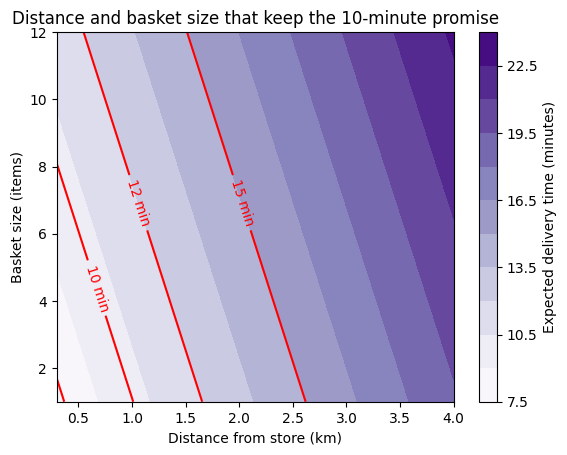

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import os

# Ensure required variables are defined in the workspace
if 'D' not in globals() or 'B' not in globals() or 'T' not in globals():
    print("Grid variables (D, B, T) were not found in memory. Re-calculating automatically...")

    # 1. Load the dataset
    file_path = "/content/Zepto_Orders_Data (1).xlsx"
    if os.path.exists(file_path):
        df = pd.read_excel(file_path, sheet_name="Orders")
    else:
        raise FileNotFoundError("Please upload 'Zepto_Orders_Data (1).xlsx' to your Colab files to run this plot.")

    # 2. Build the meshgrid
    dist_values = np.linspace(0.3, 4, 40)
    basket_values = np.linspace(1, 12, 40)
    D, B = np.meshgrid(dist_values, basket_values)

    # 3. Fit the model and predict
    formula = LinearRegression().fit(
        df[["Distance_KM", "Basket_Size"]],
        df["Delivery_Time_Min"]
    )
    cases = pd.DataFrame({"Distance_KM": D.ravel(), "Basket_Size": B.ravel()})
    T = formula.predict(cases).reshape(D.shape)

# Plot the contour
plt.contourf(D, B, T, levels=10, cmap="Purples")
plt.colorbar(label="Expected delivery time (minutes)")

lines = plt.contour(D, B, T, levels=[8, 10, 12, 15], colors="red")
plt.clabel(lines, fmt="%d min")

plt.title("Distance and basket size that keep the 10-minute promise")
plt.xlabel("Distance from store (km)")
plt.ylabel("Basket size (items)")
plt.show()

how did the sale build up week by week in each state?-Animation plot

In [ ]:
#step-1
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Running total of sales, week by week, for each state

running = df.pivot_table(

    index='Week',

    columns='State',

    values='Order_Value',

    aggfunc='sum'

).fillna(0).cumsum()

running = running[running.iloc[-1].sort_values().index]  # smallest to largest

In [22]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib.pyplot as plt
import pandas as pd

# Safely reconstruct 'running' if it is missing from memory
if 'running' not in globals() or 'running' not in locals():
    print("'running' was not in memory. Re-calculating from active 'df'...")

    # Make sure 'Week' column exists in df
    if 'Week' not in df.columns and 'Order_Date' in df.columns:
        df['Week'] = df['Order_Date'].dt.isocalendar().week.astype(int)

    # Re-build 'running' pivot table with week-by-week cumulative sales per state
    running = df.pivot_table(
        index='Week',
        columns='State',
        values='Order_Value',
        aggfunc='sum'
    ).fillna(0).cumsum()
    running = running[running.iloc[-1].sort_values().index]  # sort smallest to largest

fig, ax = plt.subplots(figsize=(7, 5))
def draw(i):
    ax.clear()
    # Use the frame index 'i' to display cumulative sales up to that frame's week
    ax.barh(running.columns, running.iloc[i] / 1000, color="#6A189A")
    ax.set_xlim(0, running.values.max() / 1000 * 1.1)
    ax.set_title("Sales up to week " + str(running.index[i]))
    ax.set_xlabel("Sales (INR thousand)")

animation = FuncAnimation(fig, draw, frames=len(running), interval=700)

plt.close()
HTML(animation.to_jshtml())

'running' was not in memory. Re-calculating from active 'df'...


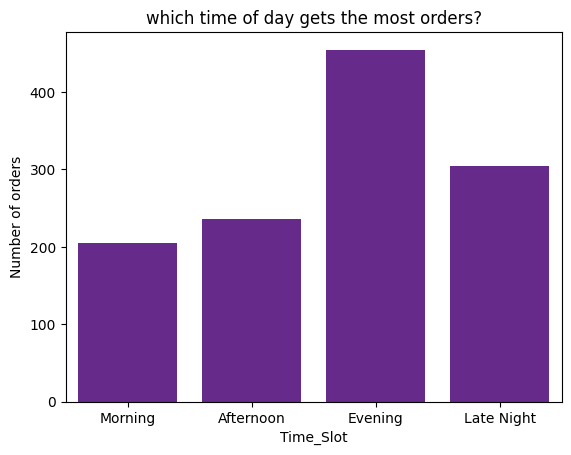

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

# Defining slot_order in case previous cells were not run
slot_order = ["Morning", "Afternoon", "Evening", "Late Night"]

# Corrected column name to 'Time_Slot' and parameter 'colour' to 'color'
sns.countplot(data=df, x="Time_Slot", order=slot_order, color="#6A1B9A")
plt.title("which time of day gets the most orders?")
plt.ylabel("Number of orders")
plt.show()

which slot is the busiest slot-Countplot

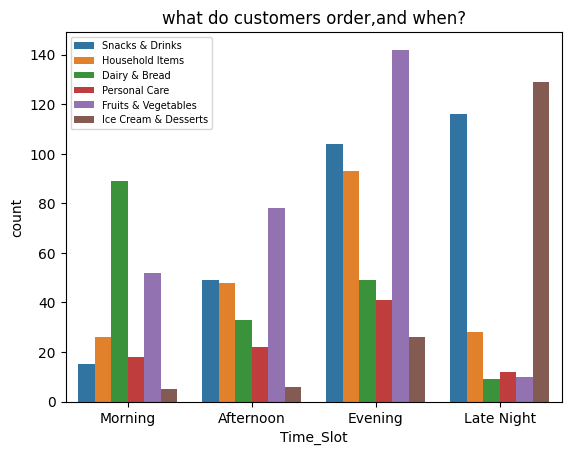

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# Corrected the syntax typo and column capitalization
sns.countplot(data=df, x="Time_Slot", order=slot_order, hue="Category")
plt.title("what do customers order,and when?")
plt.legend(fontsize=7)
plt.show()

Which time slot has the slowest and least predictable delivery

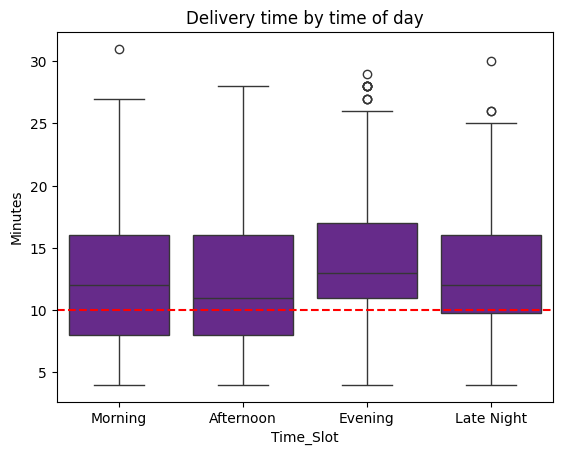

In [30]:
sns.boxplot(
    data=df,
    x="Time_Slot",
    y="Delivery_Time_Min",
    order=slot_order,
    color="#6A1B9A"
)

plt.axhline(10, color="red", linestyle="--")

plt.title("Delivery time by time of day")
plt.ylabel("Minutes")
plt.show()

Do pass members spend differently from new users?-Violin plot

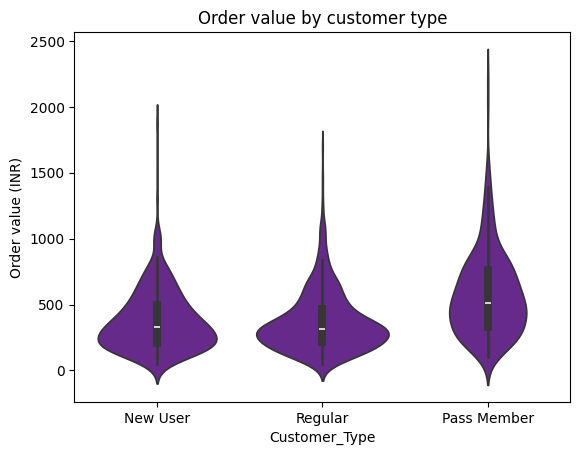

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

# Defining type_order in case previous cells were not run
type_order = ["New User", "Regular", "Pass Member"]

sns.violinplot(data=df, x="Customer_Type", y="Order_Value", order=type_order, color="#6A1B9A")

plt.title("Order value by customer type")
plt.ylabel("Order value (INR)")
plt.show()

Are low ratings cause by many orders or only a few(Strip plot)

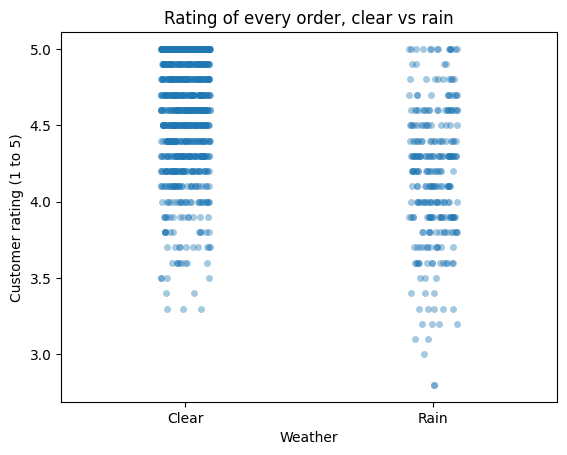

In [34]:
sns.stripplot( data=df,x="Weather",y="Customer_Rating",jitter=True,alpha=0.4)

plt.title("Rating of every order, clear vs rain")
plt.ylabel("Customer rating (1 to 5)")
plt.show()

Do Pass member really buy bigger basket-Swarm plot

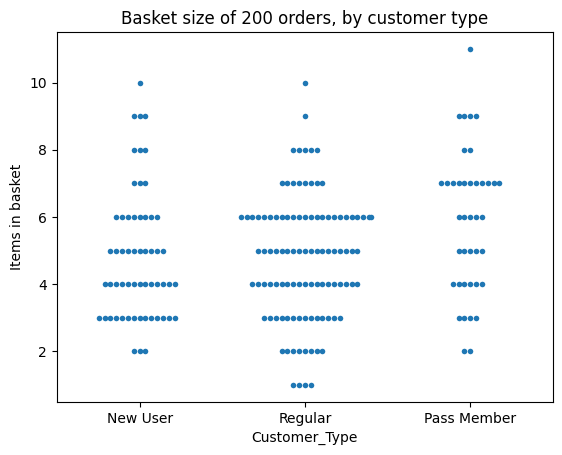

In [35]:
sample = df.sample(200, random_state=1)
sns.swarmplot(data=sample,x="Customer_Type",y="Basket_Size",order=type_order,size=4)

plt.title("Basket size of 200 orders, by customer type")
plt.ylabel("Items in basket")
plt.show()